# Ball Tree Benchmark：Exact NN/kNN + ANN/AkNN + Greedy-specific


In [52]:
from pathlib import Path
import subprocess
import itertools
import io
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt


HERE = Path.cwd().resolve()
PROJECT = next((p for p in (HERE, HERE.parent)
                if (p / "benchmark.cpp").exists()), None)

RESULTS = PROJECT / "results"
RESULTS.mkdir(exist_ok=True)
EXE = PROJECT / ("benchmark.exe" if sys.platform == "win32" else "benchmark")

sources = [
    "benchmark.cpp", "MedianSplit.cpp", "TopDown.cpp", "FarthestPivot.cpp",
    "GreedyTree.cpp", "NearestNeighbor.cpp", "KNearestNeighbor.cpp",
    "ApproxNN.cpp", "ApproxKNN.cpp", "GreedyANN.cpp", "GreedyAKNN.cpp",
]
missing = [s for s in sources if not (PROJECT / s).is_file()]
if missing:
    raise FileNotFoundError(f"C++ files: {missing}")

command = [os.environ.get("CXX", "g++"), "-std=c++17", "-O2", "-DNDEBUG",
           "-I", str(PROJECT), *[str(PROJECT / s) for s in sources],
           "-o", str(EXE)]
result = subprocess.run(command, capture_output=True, text=True)
if result.returncode != 0:
    print(result.stdout)
    print(result.stderr)
    raise RuntimeError("C++ compiler error")
print("C++ compling succeds：", EXE)


C++ compling succeds： /Users/brighthsu/Desktop/Vscode Project/C Programming/Ball_Tree/benchmark


## 2. 单组冒烟测试：18 行结果


In [ ]:
def run_case(n=200, dim=2, queries=100, k=5,
             seed=42, dataset="uniform", eps=0.25):
    command = [str(EXE), str(n), str(dim), str(queries),
               str(k), str(seed), dataset, str(eps)]
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"Benchmark fails: {command}\n{result.stderr}")
    return pd.read_csv(io.StringIO(result.stdout))

small = run_case()
display(small[["method", "search_impl", "query_type", "eps",
               "build_ms", "avg_query_us", "correct",
               "sample_mean_distance_ratio"]])
assert len(small) == 18  
assert small["correct"].eq("PASS").all()


,method,search_impl,query_type,eps,build_ms,avg_query_us,correct,sample_mean_distance_ratio
0,Median,Generic,NN,0.25,0.066625,0.41750,PASS,1.000000
1,Median,Generic,kNN,0.25,0.066625,1.04375,PASS,1.000000
2,Median,Generic,ANN,0.25,0.066625,0.32500,PASS,1.000000
3,Median,Generic,AkNN,0.25,0.066625,0.90834,PASS,1.035607
4,TopDown,Generic,NN,0.25,0.611667,0.31833,PASS,1.000000
5,TopDown,Generic,kNN,0.25,0.611667,1.09125,PASS,1.000000
6,TopDown,Generic,ANN,0.25,0.611667,0.40958,PASS,1.003085
7,TopDown,Generic,AkNN,0.25,0.611667,1.00667,PASS,1.011033
8,FarthestPivot,Generic,NN,0.25,0.046500,0.40417,PASS,1.000000
9,FarthestPivot,Generic,kNN,0.25,0.046500,1.25167,PASS,1.000000


## 3. Parameters 


In [ ]:
NS = [500, 1000, 3000,]                  # data set
DIMS = [2, 5, 10]                        # Dimensions
KS = [1, 5, 10]                          # kNN parameters
EPS = [0.0, 0.1, 0.25, 0.5]              # approximation error
DATASETS = ["uniform", "clusters"]    # "duplicates"
SEEDS = [52, 55, 63, 74]              # Seed
QUERIES = 500                        # 

frames = []
all_cases = list(itertools.product(NS, DIMS, KS, EPS, DATASETS, SEEDS))
print("Experiment：", len(all_cases))

for n, dim, k, eps, dataset, seed in all_cases:
    frames.append(run_case(n=n, dim=dim, queries=QUERIES,
                           k=k, seed=seed, dataset=dataset, eps=eps))

df = pd.concat(frames, ignore_index=True)
assert df["correct"].eq("PASS").all(), "verifing"
assert len(df) == 18 * len(all_cases), "Output 18 rows"

csv_path = RESULTS / "results.csv"
df.to_csv(csv_path, index=False)
print("Save as", csv_path)
display(df.head(12))


运行实验组数： 864


In [35]:
subset = df.query("dataset == 'uniform' and dim == 2 and k == 5 and eps == 0.25")
summary = (subset.groupby(["method", "search_impl", "query_type", "n"], as_index=False)
           .agg(build_ms=("build_ms", "mean"),
                avg_query_us=("avg_query_us", "mean"),
                tree_height=("tree_height", "mean"),
                sample_ratio=("sample_mean_distance_ratio", "mean"),
                sample_recall=("sample_recall_at_k", "mean")))
display(summary.round(3))


,method,search_impl,query_type,n,build_ms,avg_query_us,tree_height,sample_ratio,sample_recall
0,FarthestPivot,Generic,ANN,500,0.127,0.508,13.25,1.011,0.833
1,FarthestPivot,Generic,ANN,1000,0.272,0.617,14.50,1.012,0.917
2,FarthestPivot,Generic,ANN,3000,0.884,0.889,16.50,1.016,0.875
3,FarthestPivot,Generic,AkNN,500,0.127,1.144,13.25,1.061,0.867
4,FarthestPivot,Generic,AkNN,1000,0.272,1.311,14.50,1.051,0.888
5,FarthestPivot,Generic,AkNN,3000,0.884,1.728,16.50,1.053,0.875
6,FarthestPivot,Generic,NN,500,0.127,0.447,13.25,1.000,1.000
7,FarthestPivot,Generic,NN,1000,0.272,0.559,14.50,1.000,1.000
8,FarthestPivot,Generic,NN,3000,0.884,0.864,16.50,1.000,1.000
9,FarthestPivot,Generic,kNN,500,0.127,1.334,13.25,1.000,1.000


## 5. Tree construction time vs #data


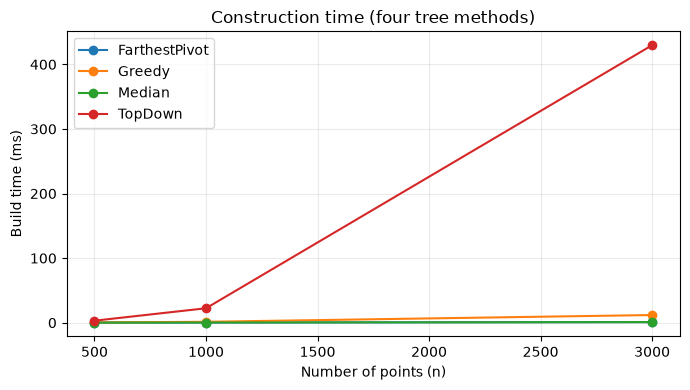

In [48]:
plot_data = df.query("dataset == 'uniform' and dim == 2 and k == 5 and "
                     "eps == 0.25 and search_impl == 'Generic' and query_type == 'NN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby("method"):
    s = g.groupby("n")["build_ms"].mean().sort_index()
    ax.plot(s.index, s.values, marker="o", label=method)
ax.set(xlabel="Number of points (n)", ylabel="Build time (ms)",
       title="Construction time (four tree methods)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "build_time.png", dpi=160)
plt.show()


## 6. Generic Exact NN time vs #data


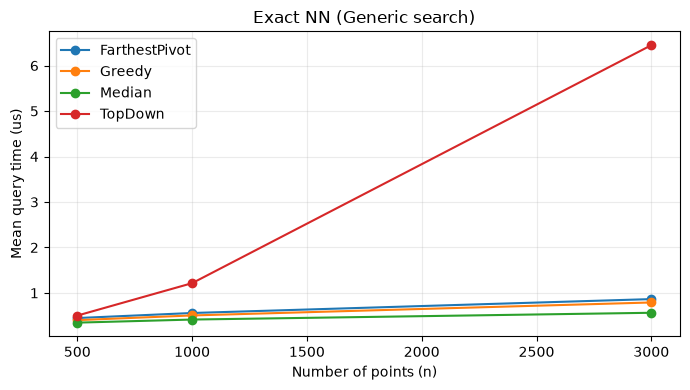

In [47]:
plot_data = df.query("dataset == 'uniform' and dim == 2 and k == 5 and "
                     "eps == 0.25 and search_impl == 'Generic' and query_type == 'NN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby("method"):
    s = g.groupby("n")["avg_query_us"].mean().sort_index()
    ax.plot(s.index, s.values, marker="o", label=method)
ax.set(xlabel="Number of points (n)", ylabel="Mean query time (us)",
       title="Exact NN (Generic search)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "nn_time.png", dpi=160)
plt.show()


## 7. Generic Exact kNN query time vs k


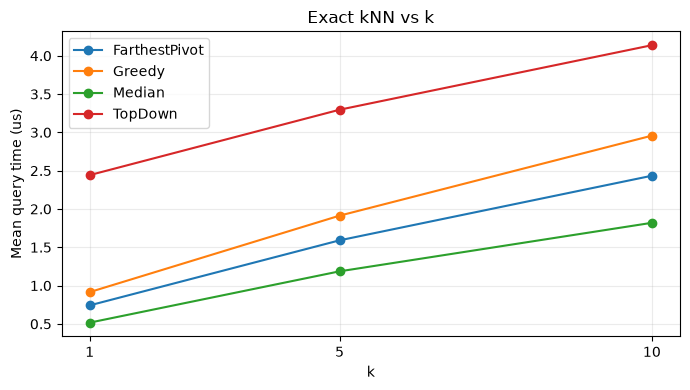

In [38]:
plot_data = df.query("dataset == 'uniform' and dim == 2 and n == 1000 and "
                     "eps == 0.25 and search_impl == 'Generic' and query_type == 'kNN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby("method"):
    s = g.groupby("k")["avg_query_us"].mean().sort_index()
    ax.plot(s.index, s.values, marker="o", label=method)
ax.set(xlabel="k", ylabel="Mean query time (us)", title="Exact kNN vs k")
ax.set_xticks(KS)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "knn_vs_k.png", dpi=160)
plt.show()


## 8. Dimension for Generic Exact NN


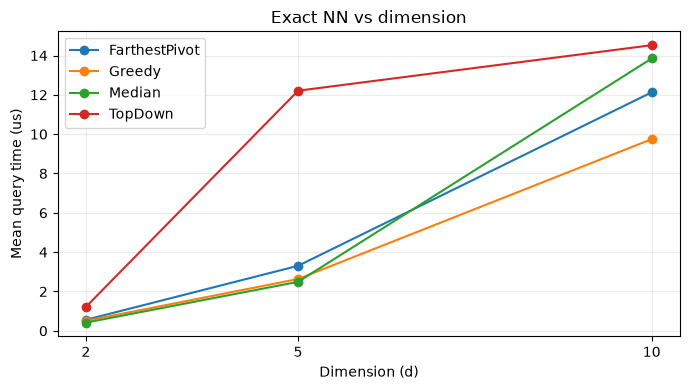

In [39]:
plot_data = df.query("dataset == 'uniform' and n == 1000 and k == 5 and "
                     "eps == 0.25 and search_impl == 'Generic' and query_type == 'NN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby("method"):
    s = g.groupby("dim")["avg_query_us"].mean().sort_index()
    ax.plot(s.index, s.values, marker="o", label=method)
ax.set(xlabel="Dimension (d)", ylabel="Mean query time (us)",
       title="Exact NN vs dimension")
ax.set_xticks(DIMS)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "nn_vs_dimension.png", dpi=160)
plt.show()


## 9. data distribution of Generic Exact NN


method,FarthestPivot,Greedy,Median,TopDown
dataset,,,,
clusters,0.557,0.506,0.764,0.490
uniform,0.559,0.505,0.414,1.215


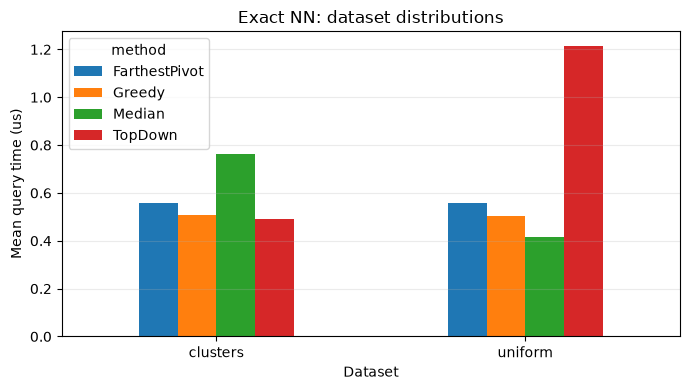

In [40]:
plot_data = df.query("n == 1000 and dim == 2 and k == 5 and eps == 0.25 and "
                     "search_impl == 'Generic' and query_type == 'NN'")
summary_dist = (plot_data.groupby(["dataset", "method"])["avg_query_us"]
                .mean().unstack("method"))
display(summary_dist.round(3))
ax = summary_dist.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set(xlabel="Dataset", ylabel="Mean query time (us)",
       title="Exact NN: dataset distributions")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS / "nn_vs_distribution.png", dpi=160)
plt.show()


## 10. Generic ANN：query time vs ε

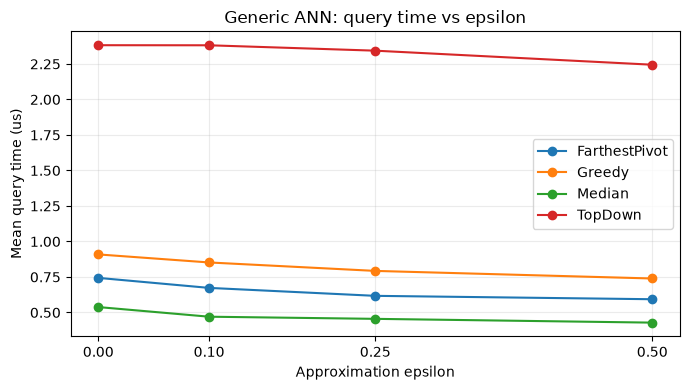

In [41]:

plot_data = df.query("dataset == 'uniform' and n == 1000 and dim == 2 and k == 5 and "
                     "search_impl == 'Generic' and query_type == 'ANN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby('method'):
    s = g.groupby('eps')['avg_query_us'].mean().sort_index()
    ax.plot(s.index, s.values, marker='o', label=method)
ax.set(xlabel='Approximation epsilon', ylabel='Mean query time (us)',
       title='Generic ANN: query time vs epsilon')
ax.set_xticks(EPS)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'ann_vs_epsilon.png', dpi=160)
plt.show()


## 11. Generic AkNN：query time vs ε

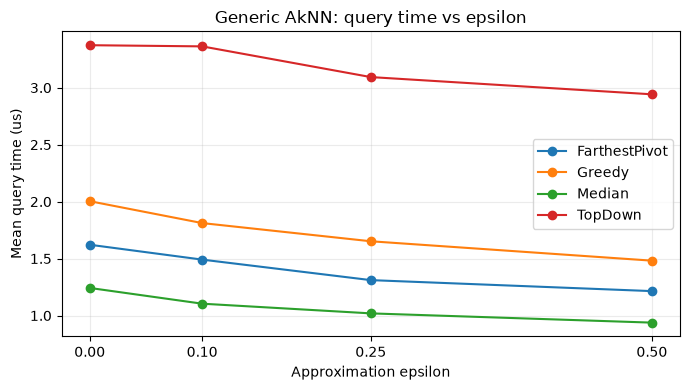

In [42]:

plot_data = df.query("dataset == 'uniform' and n == 1000 and dim == 2 and k == 5 and "
                     "search_impl == 'Generic' and query_type == 'AkNN'")
fig, ax = plt.subplots(figsize=(7, 4))
for method, g in plot_data.groupby('method'):
    s = g.groupby('eps')['avg_query_us'].mean().sort_index()
    ax.plot(s.index, s.values, marker='o', label=method)
ax.set(xlabel='Approximation epsilon', ylabel='Mean query time (us)',
       title='Generic AkNN: query time vs epsilon')
ax.set_xticks(EPS)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'aknn_vs_epsilon.png', dpi=160)
plt.show()


## 12. Greedy：Generic vs specific query time

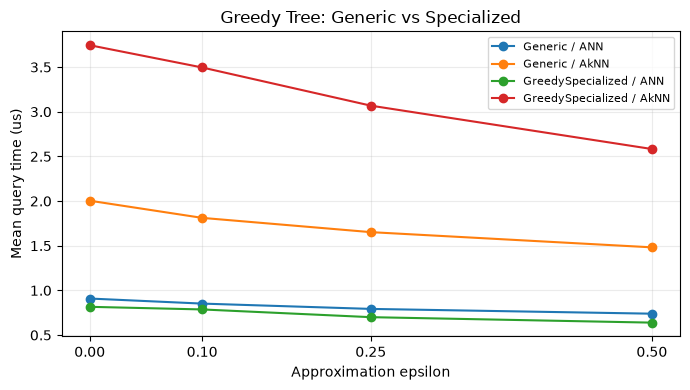

In [ ]:

plot_data = df.query("dataset == 'uniform' and n == 1000 and dim == 2 and k == 5 and "
                     "method == 'Greedy' and query_type in ['ANN', 'AkNN']")
fig, ax = plt.subplots(figsize=(7, 4))
for (impl, task), g in plot_data.groupby(['search_impl', 'query_type']):
    s = g.groupby('eps')['avg_query_us'].mean().sort_index()
    ax.plot(s.index, s.values, marker='o', label=f'{impl} / {task}')
ax.set(xlabel='Approximation epsilon', ylabel='Mean query time (us)',
       title='Greedy Tree: Generic vs specific')
ax.set_xticks(EPS)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'greedy_generic_vs_specific.png', dpi=160)
plt.show()


## 13. Distance error

,method,search_impl,query_type,eps,sample_mean_distance_ratio,sample_max_distance_ratio,sample_recall_at_k
0,FarthestPivot,Generic,ANN,0.00,1.0000,1.0000,1.0000
1,FarthestPivot,Generic,ANN,0.10,1.0008,1.0361,0.9792
2,FarthestPivot,Generic,ANN,0.25,1.0119,1.2440,0.9167
3,FarthestPivot,Generic,ANN,0.50,1.0629,1.4431,0.7917
4,FarthestPivot,Generic,AkNN,0.00,1.0000,1.0000,1.0000
5,FarthestPivot,Generic,AkNN,0.10,1.0085,1.0943,0.9542
6,FarthestPivot,Generic,AkNN,0.25,1.0512,1.2450,0.8875
7,FarthestPivot,Generic,AkNN,0.50,1.1524,1.4852,0.8167
8,Greedy,Generic,ANN,0.00,1.0000,1.0000,1.0000
9,Greedy,Generic,ANN,0.10,1.0024,1.0795,0.9583


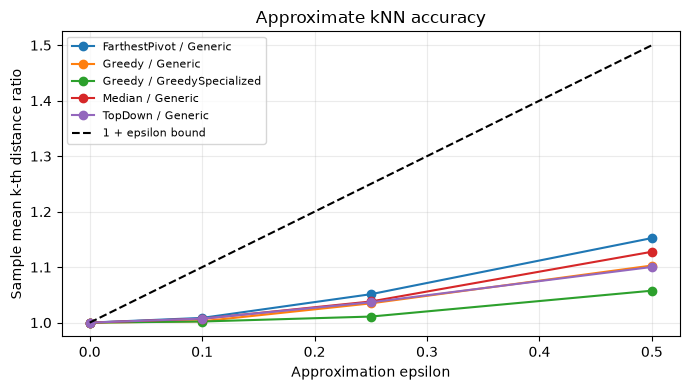

In [50]:

quality = df.query("dataset == 'uniform' and n == 1000 and dim == 2 and k == 5 and "
                   "query_type in ['ANN', 'AkNN']")
quality_summary = (quality.groupby(['method', 'search_impl', 'query_type', 'eps'],
                                   as_index=False)
                   .agg(sample_mean_distance_ratio=('sample_mean_distance_ratio', 'mean'),
                        sample_max_distance_ratio=('sample_max_distance_ratio', 'max'),
                        sample_recall_at_k=('sample_recall_at_k', 'mean')))
display(quality_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for (method, impl), g in quality.query("query_type == 'AkNN'").groupby(['method','search_impl']):
    s = g.groupby('eps')['sample_mean_distance_ratio'].mean().sort_index()
    ax.plot(s.index, s.values, marker='o', label=f'{method} / {impl}')
ax.plot(EPS, [1+e for e in EPS], linestyle='--', color='black', label='1 + epsilon bound')
ax.set(xlabel='Approximation epsilon', ylabel='Sample mean k-th distance ratio',
       title='Approximate kNN accuracy')
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'aknn_accuracy.png', dpi=160)
plt.show()


## 14. Distance and error on greedy tree

,search_impl,query_type,eps,avg_nodes_visited,avg_distance_computations,avg_query_us
0,Generic,ANN,0.00,42.82,81.66,0.91
1,Generic,ANN,0.10,40.38,77.39,0.85
2,Generic,ANN,0.25,38.36,73.80,0.79
3,Generic,ANN,0.50,36.36,70.19,0.74
4,Generic,AkNN,0.00,76.83,135.10,2.00
5,Generic,AkNN,0.10,70.06,124.18,1.81
6,Generic,AkNN,0.25,64.40,115.01,1.65
7,Generic,AkNN,0.50,58.94,105.99,1.48
8,GreedySpecialized,ANN,0.00,32.35,32.35,0.82
9,GreedySpecialized,ANN,0.10,30.04,31.04,0.79


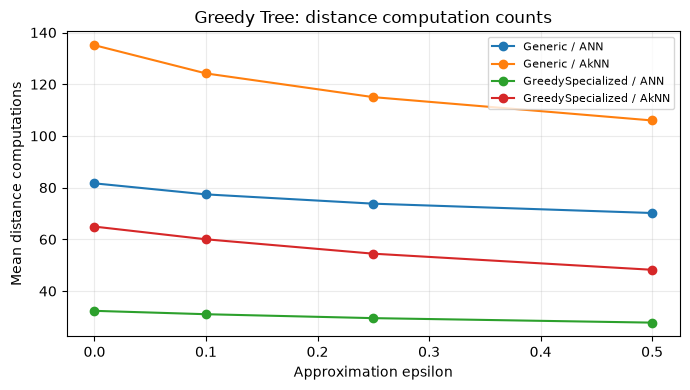

In [49]:

sub = df.query("dataset == 'uniform' and n == 1000 and dim == 2 and k == 5 and "
               "method == 'Greedy' and query_type in ['ANN', 'AkNN']")
counters = (sub.groupby(['search_impl','query_type','eps'], as_index=False)
            .agg(avg_nodes_visited=('avg_nodes_visited','mean'),
                 avg_distance_computations=('avg_distance_computations','mean'),
                 avg_query_us=('avg_query_us','mean')))
display(counters.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
for (impl, typ), g in sub.groupby(['search_impl', 'query_type']):
    s = g.groupby('eps')['avg_distance_computations'].mean().sort_index()
    ax.plot(s.index, s.values, marker='o', label=f'{impl} / {typ}')
ax.set(xlabel='Approximation epsilon', ylabel='Mean distance computations',
       title='Greedy Tree: distance computation counts')
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'greedy_distance_computations.png', dpi=160)
plt.show()
